## Setup

In [ ]:
!pip install update tensorflow
!pip install  tensorflow-text tensorflow-hub

import locale
locale.getpreferredencoding = lambda: "UTF-8"
import keras
import pandas as pd
import os
import sentencepiece as spm
import numpy as np
import re
import tensorflow_text as tf_text
import tensorflow as tf
import requests
import math
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow_hub as hub
import plotly.express as px
import tensorflow_datasets as tfds
import random


from tensorflow.data.experimental import make_csv_dataset
from keras import layers
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
from sklearn.utils import compute_class_weight

from tqdm import tqdm

from transformers import BertTokenizer, AutoTokenizer

tf.compat.v1.enable_v2_behavior()
tqdm.pandas()

sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (20,8)
plt.rcParams['font.size'] = 18



## Implememnt Transfromrer

In [ ]:
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = keras.Sequential(
            [layers.Dense(ff_dim, activation="sigmoid"), layers.Dense(embed_dim),]
        )
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-9)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-9)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)

    def call(self, inputs):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output)
        return self.layernorm2(out1 + ffn_output)

## Implementing embedding layer

In [ ]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super(TokenAndPositionEmbedding, self).__init__()
        self.token_emb = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = layers.Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions


## Tokenization and embedding

### Setup

### Read data from file

In [ ]:
from google.colab import drive
from google.colab import data_table
from vega_datasets import data

data_table.enable_dataframe_formatter()

data.airports()

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
config = {
  'seed': 37,
  'batch_size': 64,
  'epochs': 46,
  'max_seq_len': 728
}

#### Extracts only 'text' and 'true_sentiment' from csv file

In [ ]:


dir = "/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv"
le = LabelEncoder()



# dataset1 = make_csv_dataset(dir,
#           config['batch_size'], label_name='true_sentiment',
#           num_epochs=config['epochs'], shuffle_seed=37)
sent_o = pd.read_csv(dir, delimiter=',', quotechar='"')
#dir = "/content/drive/MyDrive/HLT project/Project files/finance_news_data.xlsx"


# sent2_o = pd.read_excel(dir, header=1, names=['true_sentiment', 'text'])



# sent2_o['true_sentiment'] = sent2_o['true_sentiment'].apply(lambda d: d.title())

# sent2_o = sent2_o.reindex(columns=['text', 'true_sentiment'])
sent_o = sent_o [['title', 'true_sentiment']]
#sent1 = pd.concat([sent_o, sent2_o])
sent1 = sent_o
sent1.reset_index(drop=True, inplace=True)
sent1[:10]



,title,true_sentiment
0,Euro to benefit from the ECBs pronounced hawki...,Positive
1,EURCHF Trend higher may remain in place – ING,Positive
2,Does a jump in EURCHF point to a break above 1...,Neutral
3,EURCHF could extend its advance back to levels...,Positive
4,EURCHF to head higher towards 10130 and projec...,Positive
5,EURCHF Room for the Euro to extend the move hi...,Positive
6,USDCHF stalls its run higher at the 200 bar MA...,Neutral
7,EURCHF reaches 38.2% of the 2 year range as ru...,Positive
8,EURCHF Bias would be for stronger Franc but wa...,Negative
9,New lows for the EURUSD. EURCHF down as well a...,Negative


In [ ]:
px.bar(sent1.groupby('true_sentiment').count().reset_index(), x='title',  color="true_sentiment", title='Count of Pos, Neg, Neu sentiments in the headlines')

In [13]:
sent1['sentence_length'] = sent1['title'].apply(lambda x: len(x.split()))
px.histogram(sent1, x="sentence_length",height=700, color='true_sentiment', title="Title Length Distribution")

In [ ]:

pos = sent1[sent1['true_sentiment']=='Positive']['text'].tolist()
neut = sent1[sent1['true_sentiment']=='Neutral']['text'].tolist()
neg = sent1[sent1['true_sentiment']=='Negative']['text'].tolist()


### The  Most Present Words

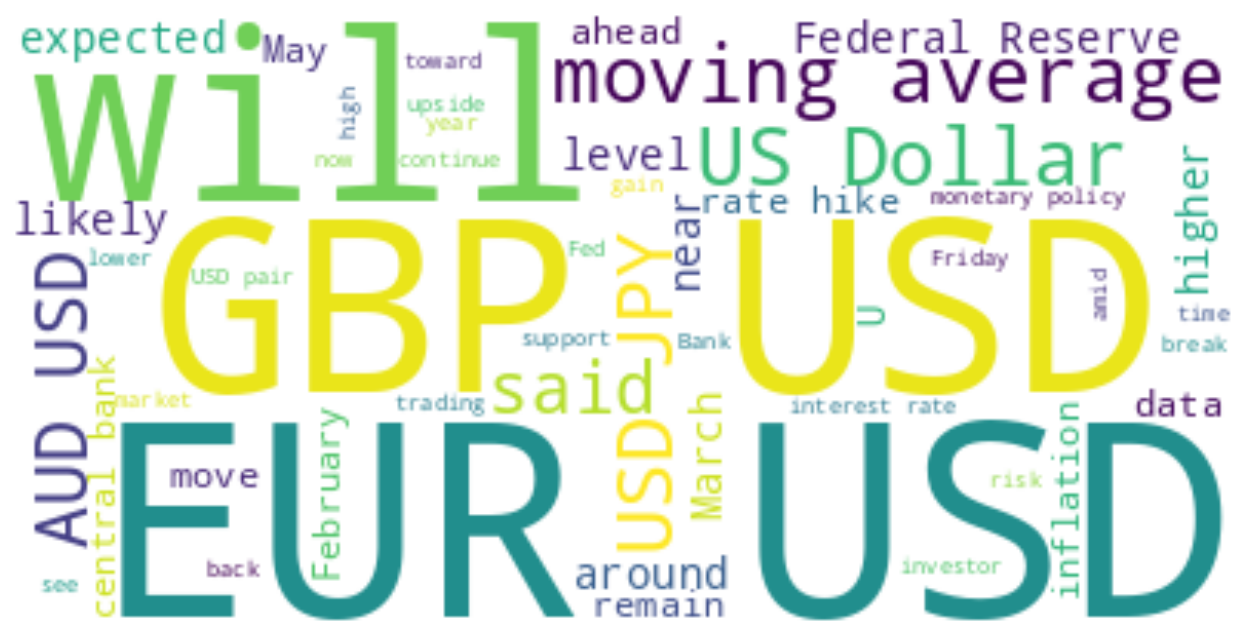

In [ ]:
wordcloud = WordCloud(max_words=50, width=400, background_color='white').generate(" ".join(pos))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()


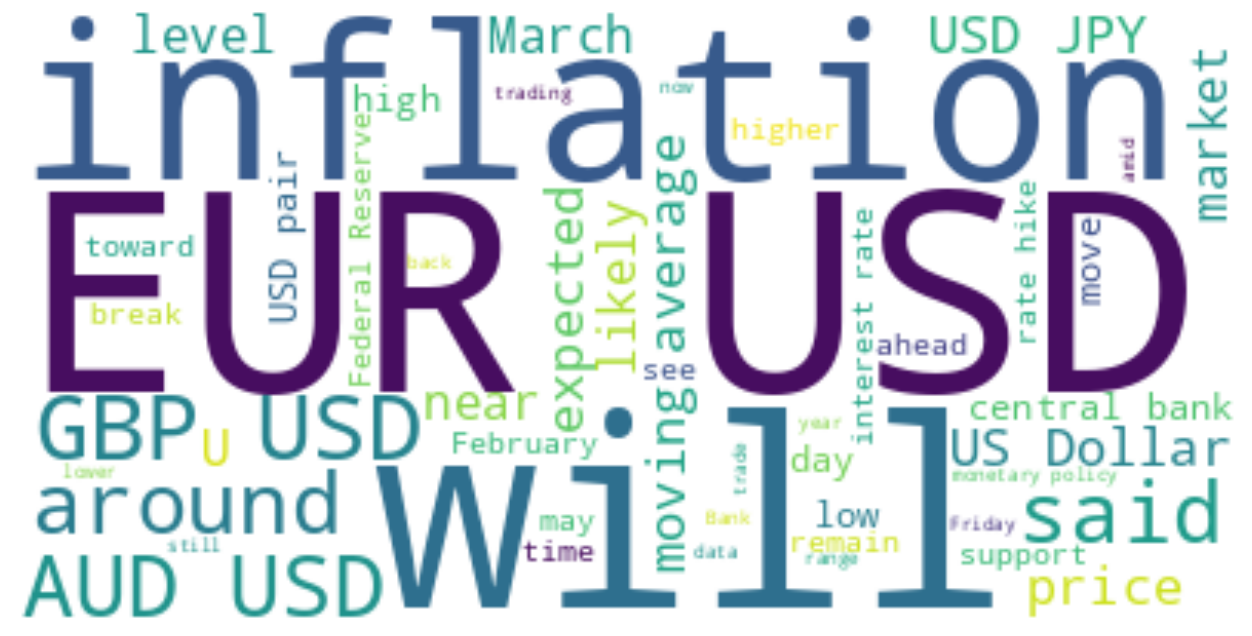

In [ ]:
wordcloud = WordCloud(max_words=50, width=400, background_color='white').generate(" ".join(neut))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

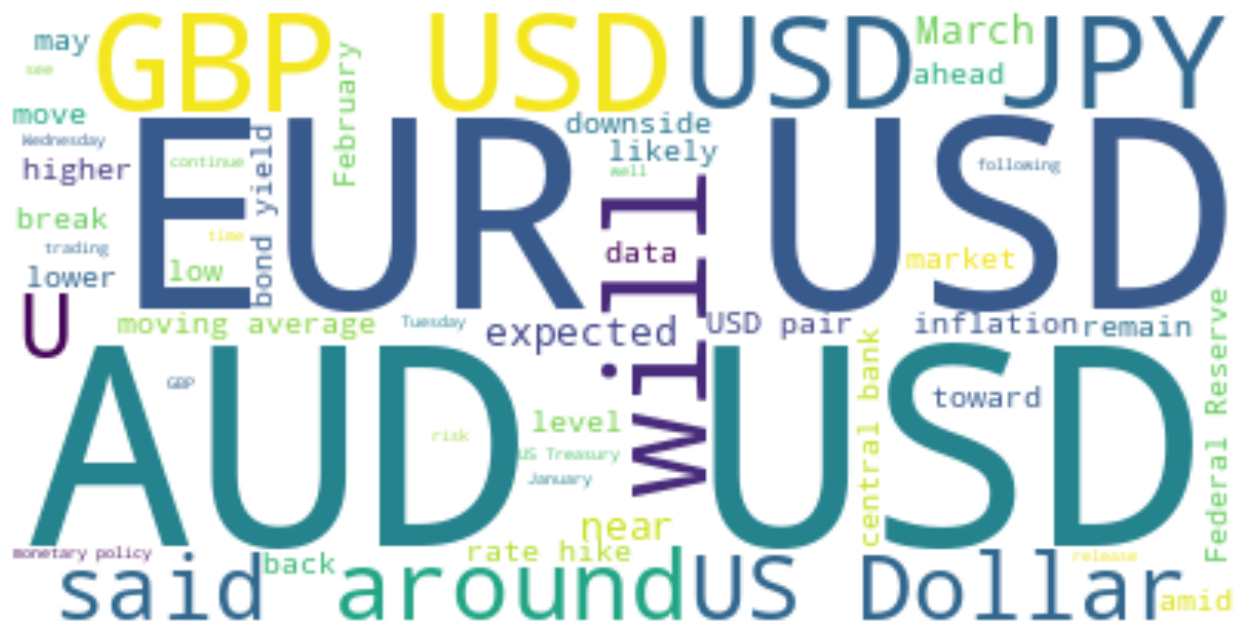

In [ ]:
wordcloud = WordCloud(max_words=50, width=400, background_color='white').generate(" ".join(neg))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()


### Transforms the Dataframe in DataSet

In [ ]:


sent = {'text': sent1['text'], 'target': sent1['true_sentiment']}


sent['target'] = to_categorical(le.fit_transform(sent['target']))

classWeight = compute_class_weight(class_weight='balanced', classes=np.unique(sent1['true_sentiment']), y=sent1['true_sentiment'])

tf.data.experimental.enable_debug_mode()

dataset = tf.data.Dataset.from_tensor_slices(sent).shuffle(1024)

dataset_size =  dataset.cardinality().numpy()
dataset_size

2291

In [ ]:
# preprocessor = hub.KerasLayer(
#     "https://kaggle.com/models/tensorflow/bert/frameworks/TensorFlow2/variations/en-uncased-preprocess/versions/3")
# encoder = hub.KerasLayer(
#     "https://www.kaggle.com/models/google/universal-sentence-encoder/frameworks/TensorFlow2/variations/cmlm-en-base/versions/1")


#### Download the pretrained BERT model


In [ ]:
# BERT_URL = "https://tfhub.dev/tensorflow/bert_en_uncased_L-12_H-768_A-12/1"
# bert_layer = hub.KerasLayer(BERT_URL, trainable=True)

# vocab_file = bert_layer.resolved_object.vocab_file.asset_path.numpy()
# do_lower_case = bert_layer.resolved_object.do_lower_case.numpy()

In [ ]:
# def load_vocab(vocab_file):
#   """Load a vocabulary file into a list."""
#   vocab = []
#   with tf.io.gfile.GFile(vocab_file, "r") as reader:
#     while True:
#       token = reader.readline()
#       if not token: break
#       token = token.strip()
#       vocab.append(token)
#   return vocab

# vocab = load_vocab(vocab_file)

In [ ]:
# def create_vocab_table(vocab, num_oov=1):
#   """Create a lookup table for a vocabulary"""
#   vocab_values = tf.range(tf.size(vocab, out_type=tf.int64), dtype=tf.int64)
#   init = tf.lookup.KeyValueTensorInitializer(keys=vocab, values=vocab_values, key_dtype=tf.string, value_dtype=tf.int64)
#   vocab_table = tf.lookup.StaticVocabularyTable(init, num_oov, lookup_key_dtype=tf.string)
#   return vocab_table

# vocab_lookup_table = create_vocab_table(vocab)

In [ ]:
# def create_index2word(vocab):
#   # Create a lookup table for a index to token
#   vocab_values = tf.range(tf.size(vocab, out_type=tf.int64), dtype=tf.int64)
#   init = tf.lookup.KeyValueTensorInitializer(keys=vocab_values, values=vocab)
#   return tf.lookup.StaticHashTable(initializer=init, default_value=tf.constant('unk'), name="index2word")

# index2word = create_index2word(vocab)

### Gets the pre-trained LLama model for tokenization

In [ ]:


hf_tok = AutoTokenizer.from_pretrained("codellama/CodeLlama-7b-Python-hf", trust_remote_code=True)

if hf_tok.pad_token is None:
    hf_tok.add_special_tokens({'pad_token': '[PAD]'})

# tokenizer = tf_text.BertTokenizer(
#     vocab_lookup_table,
#     token_out_type=tf.int64,
#     lower_case=do_lower_case,
#     keep_whitespace=True,
#     suffix_indicator='##',
#     split_unknown_characters=True,

#   )



/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:88: UserWarning:


The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.



tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

In [ ]:
PAD_ID = 0 #vocab_lookup_table.lookup(tf.constant('[PAD]')) # padding token
# CLS_ID = vocab_lookup_table.lookup(tf.constant('[CLS]')) # class token
# SEP_ID = vocab_lookup_table.lookup(tf.constant('[SEP]')) # sequence separator token
# print("PAD token: {} \nCLS token: {} \nSEP token: {}".format(PAD_ID, CLS_ID, SEP_ID))


### Transforms text into tokens, truncates and pads

In [ ]:

def preprocess(news, label):
  # process review to calculate BERT input)
  ids = preprocess_bert_input(news)

  # with tf.compat.v1.Session() as sess:
  #   ids_numpy = ids.eval(session=sess)
  return ids, label

def preprocess_bert_input(review):
  # calculate tokens ID
  ids = tokenize_text(review, config['max_seq_len'])
  return ids

def tokenize_text(news, seq_len):
  # convert text into token ids

  tokens = hf_tok.encode(news.numpy().decode(), max_length=config['max_seq_len'], add_special_tokens=True, truncation=True, padding=True)
  sent_len = len(tokens)
  if sent_len > seq_len:
    tokens = tokens[:seq_len]
  elif sent_len < seq_len:
    tokens += [PAD_ID] * (seq_len - sent_len)
  # print(tokens.merge_dims(1, 2)[:, :seq_len])
  # # flatten the output ragged tensors
  #tokens = tokens.merge_dims(1, 2)
  # # Add start and end token ids to the id sequence
  # start_tokens = tf.fill([tf.shape(news)[0], 1], CLS_ID)
  # end_tokens = tf.fill([tf.shape(news)[0], 1], SEP_ID)
  # tokens = tokens[:, :seq_len - 2]
  # tokens = tf.concat([start_tokens, tokens, end_tokens], axis=1)
  # # truncate sequences greater than MAX_SEQ_LEN
  # tokens = tokens[:, :seq_len]
  # # pad shorter sequences with the pad token id
  # tokens = tokens.to_tensor(default_value=PAD_ID)
  #
  # tokens = tf.pad(tokens, [[0, 0], [0, pad]], constant_values=PAD_ID)

  # and finally reshape the word token ids to fit the output
  # data structure of TFT
  #return tf.reshape(tokens, [-1, seq_len])
  return tokens


### Splits the data set

In [ ]:
train_size = int(0.7 * dataset_size)
val_size = int(0.15 * dataset_size)
test_size = int(0.15 * dataset_size)


train_dataset = dataset.take(train_size)
test_dataset = dataset.skip(train_size)
val_dataset = test_dataset.skip(val_size)
test_dataset = test_dataset.take(test_size)





### Apply the acctual preprocess function and reshape the dataset

In [ ]:
def data_rescale(y_dim, d):
  return tf.ensure_shape(d, y_dim)

tf.config.run_functions_eagerly(True)
train_ds = train_dataset.map(lambda x: tf.py_function(preprocess, [x['text'], x['target']], [tf.int64, tf.float64]),num_parallel_calls=tf.data.AUTOTUNE)
valid_ds = val_dataset.map(lambda x: tf.py_function(preprocess, [x['text'], x['target']], [tf.int64, tf.float64]),num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_dataset.map(lambda x: tf.py_function(preprocess, [x['text'], x['target']], [tf.int64, tf.float64]),num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.map(lambda ne,le: (data_rescale(config['max_seq_len'], ne), data_rescale(3, le)))
valid_ds = valid_ds.map(lambda ne,le: (data_rescale(config['max_seq_len'], ne), data_rescale(3, le)))
test_ds = test_ds.map(lambda ne,le: (data_rescale(config['max_seq_len'], ne), data_rescale(3, le)))


train_ds = train_ds.shuffle(1024).batch(config['batch_size']).prefetch(tf.data.experimental.AUTOTUNE)
valid_ds = valid_ds.shuffle(1024).batch(config['batch_size']).prefetch(tf.data.experimental.AUTOTUNE)
test_ds = test_ds.shuffle(1024).batch(config['batch_size']).prefetch(tf.data.experimental.AUTOTUNE)

In [ ]:
ds_numpy = tfds.as_numpy(train_ds)
for ex in ds_numpy:
  print("Encode and Decode --- {}\n{}".format(ex[0][0],hf_tok.decode(ex[0][0])))
  print("Shape of input --- {}".format(ex[0].shape))
  print("Shape of label --- {}".format(ex[1].shape))
  print("Vocab size --- {}".format(hf_tok.vocab_size))
  break

Encode and Decode --- [    1   910  4098 29892   278   360 26810   756  8886 17515 29871 29941
 29995  2750   278 11652 29889  1205  6198  6554   534  1975   526  3806
   304 15381   278  7258 27550  1449   297   278  6421 11405 29892 26240
   435  2707   267 29892 14546 12002   383 29990  3767  1845   391   472
 21903 26236  6947   280 29892 13676 29889  1932   674   263 10225   310
 16200 14321  4953   263  1108   363  4092 29973  1346  1576  4565  1095
   338   544  7612   363   278 11206 29933   517  7251   446   491 29871
 29945 29900   289   567   901  1135   278 17972   297   278  2446  4832
  7378 29892   322  1550   393 30010 29879   385  7910   310   871 29871
 29941 29945   289   567   515   825   471   544  7612   297   472   278
  1095   310  5490 29892   591  2149   304  1074  6198  6554   534  1975
  1369   304 15381   278 11652  1449   297   278  6421 11405  3178  1346
  3644   727 30010 29879   263  9570   373   278 28205 29892   372  5304
   297   278   883   310  523

## Prepare the embedding

In [ ]:
embed_dim = 32  # Embedding size for each token
num_heads = 8  # Number of attention heads
ff_dim = 128 # Hidden layer size in feed forward network inside transformer

inputs = layers.Input(shape=(config['max_seq_len'],))
embedding_layer = TokenAndPositionEmbedding(config['max_seq_len'], hf_tok.vocab_size, embed_dim)
x = embedding_layer(inputs)
transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim)
x = transformer_block(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(ff_dim, activation="sigmoid")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(units=3, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

## Train and Evaluate

#### Model train

In [ ]:

# f1score = keras.metrics.F1Score(average="weighted",threshold=0.5)

# learning_rate_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
#     initial_learning_rate=0.0003,
#     decay_steps=1000,
#     decay_rate=0.96
# )

#optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate_schedule)
#optimizer = keras.optimizers.Adam(learning_rate=0.0003, epsilon=1e-08)

optimizer = keras.optimizers.SGD(learning_rate=0.000001, momentum=0.9, nesterov=True)

#optimizer = tf.keras.optimizers.Adam(learning_rate=5e-10,epsilon=1e-12,clipnorm=1.0)



model.compile(
    optimizer=optimizer, loss=tf.keras.losses.CategoricalCrossentropy(), metrics=["accuracy"],
    )

model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 728)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ token_and_position_embedding         │ (None, 728, 32)             │       1,047,296 │
│ (TokenAndPositionEmbedding)          │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_block (TransformerBlock) │ (None, 728, 32)             │          42,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,093,955 (4.17 MB)

 Trainable params: 1,093,955 (4.17 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
  # EarlyStopping: Stop training when a val_loss stops improving
  keras.callbacks.EarlyStopping(
    min_delta = 0.001,
    patience = 15,
    monitor = 'val_loss',
    mode = 'min',
    restore_best_weights = True
  ),
]
print(train_ds.element_spec)

history = model.fit(
    train_ds, epochs=config['epochs'], validation_data=valid_ds, callbacks=callbacks, class_weight= dict(enumerate(classWeight))
)

(TensorSpec(shape=(None, 728), dtype=tf.int64, name=None), TensorSpec(shape=(None, 3), dtype=tf.float64, name=None))
Epoch 1/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 32s 634ms/step - accuracy: 0.3029 - loss: 1.1849 - val_accuracy: 0.3304 - val_loss: 1.1996
Epoch 2/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 404ms/step - accuracy: 0.3285 - loss: 1.1833 - val_accuracy: 0.3449 - val_loss: 1.2026
Epoch 3/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 14s 409ms/step - accuracy: 0.3160 - loss: 1.1827 - val_accuracy: 0.3391 - val_loss: 1.1984
Epoch 4/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 435ms/step - accuracy: 0.3333 - loss: 1.1754 - val_accuracy: 0.3304 - val_loss: 1.1756
Epoch 5/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 14s 410ms/step - accuracy: 0.3158 - loss: 1.1830 - val_accuracy: 0.3275 - val_loss: 1.1782
Epoch 6/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 462ms/step - accuracy: 0.3273 - loss: 1.1877 - val_accuracy: 0.3449 - val_loss: 1.1821
Epoch 7/46
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 393ms/step - accuracy: 0.3199 - loss: 1.1941 - val_accuracy: 0.3710

#### Model Evaluate

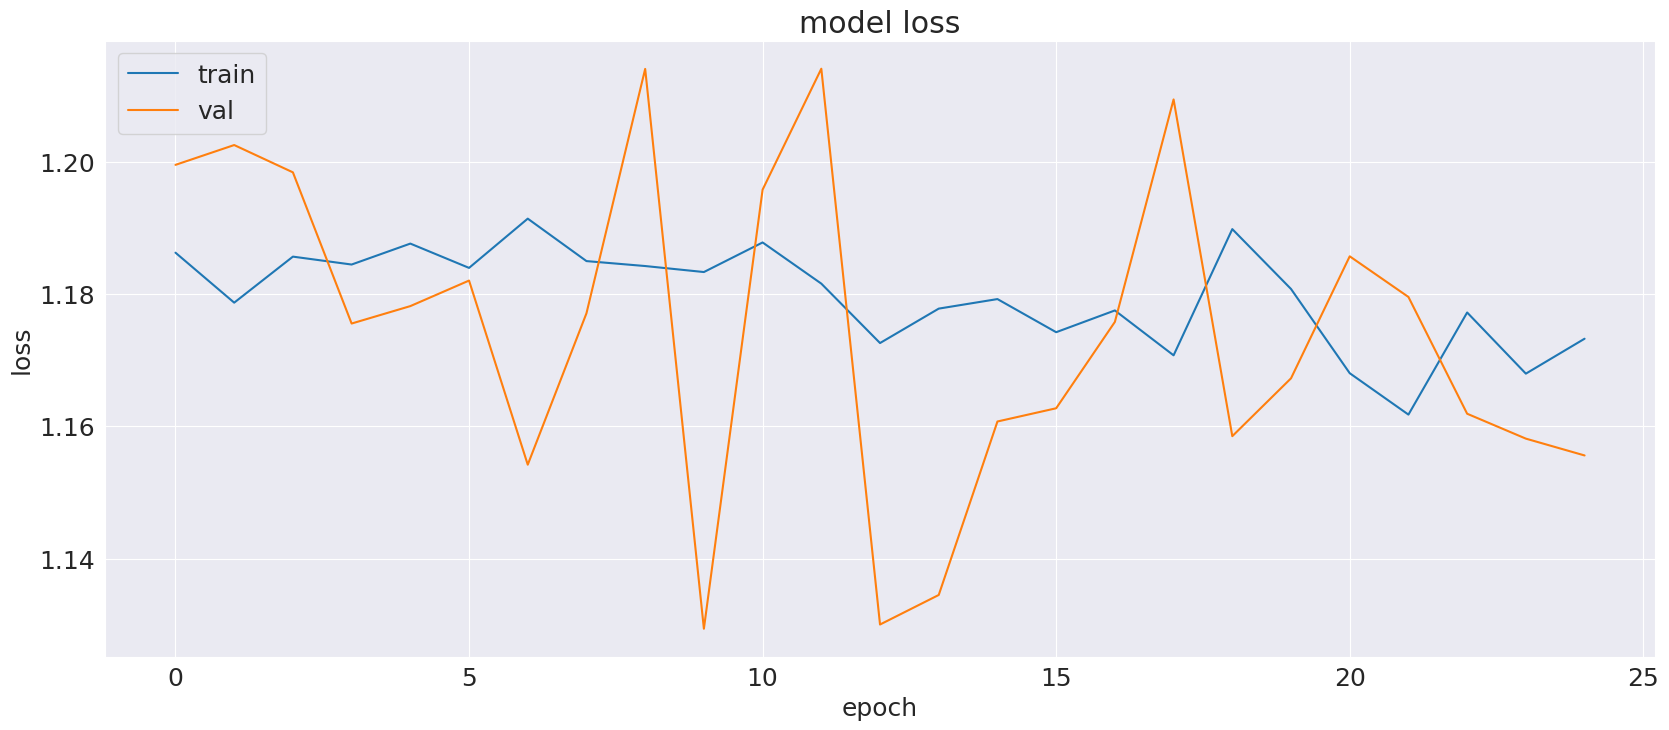

In [ ]:
plt.figure(figsize=(20,8))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

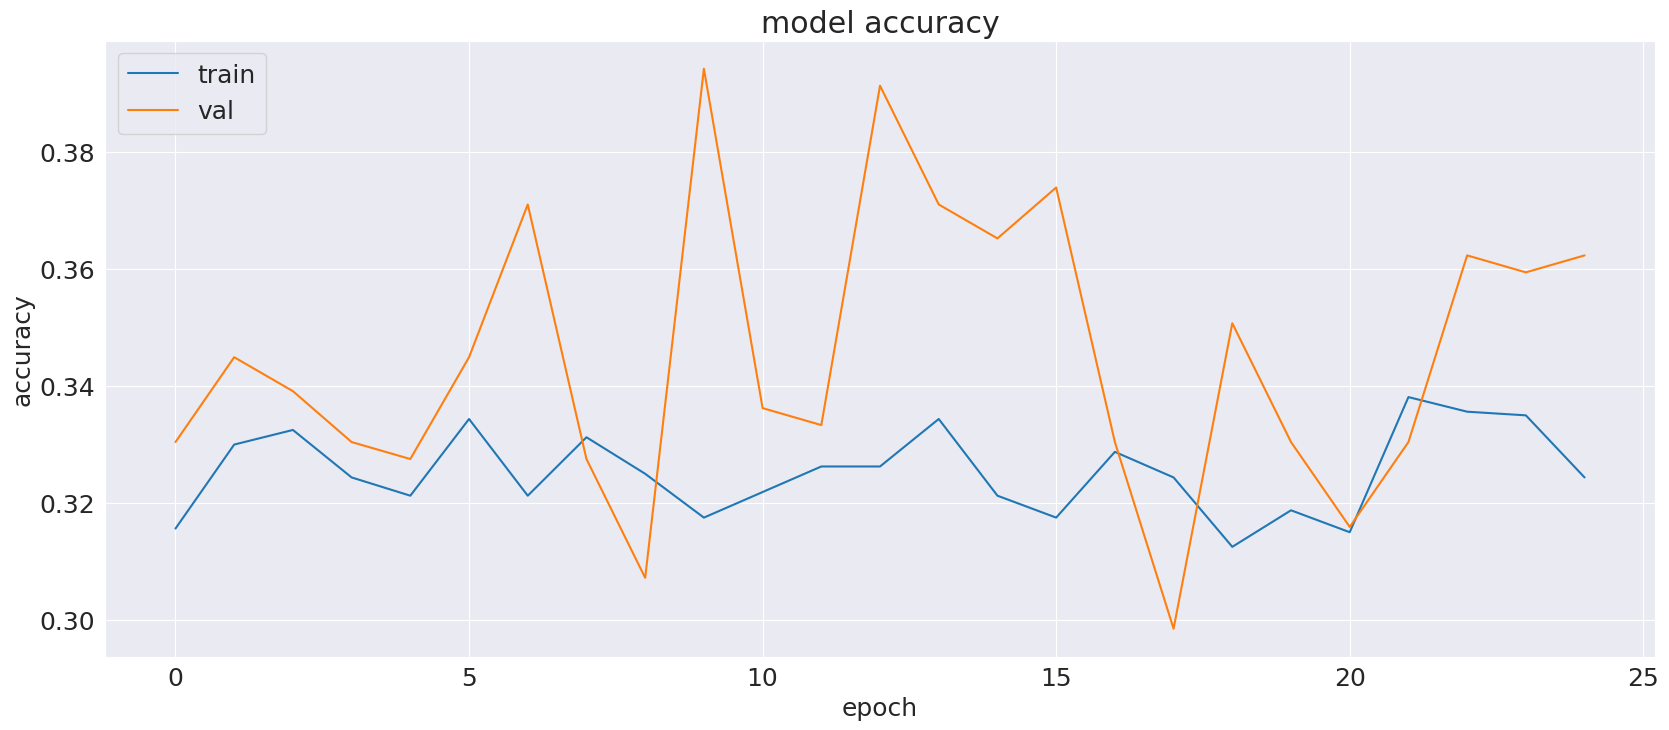

In [ ]:
plt.figure(figsize=(20,8))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

### Classification Tas

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
y_pred = model.predict(test_ds)

target = []

for tr in test_ds.unbatch().as_numpy_iterator():
  target.append(tr[1])



roc_auc = roc_auc_score(target,  y_pred,multi_class='ovo')
print(roc_auc)

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step
0.5178076647368847


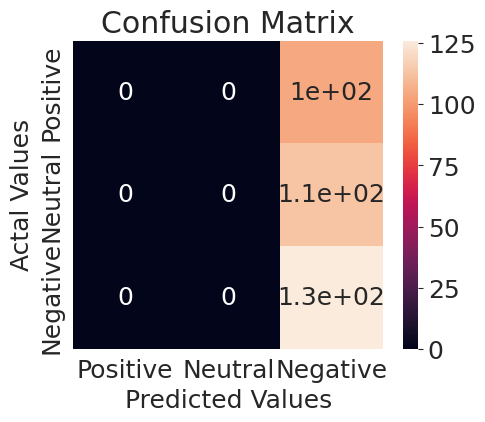

In [ ]:

target = tf.argmax(target, axis = 1).numpy()
y_pred = tf.argmax(y_pred, axis = 1).numpy()

cm = confusion_matrix(target, y_pred)

cm_df = pd.DataFrame(cm,
                     index = ['Positive','Neutral','Negative'],
                     columns = ['Positive','Neutral','Negative'])

plt.figure(figsize=(5,4))
sns.heatmap(cm_df, annot=True)
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()



In [ ]:
!pip freeze > '/content/drive/MyDrive/HLT project/Final code/requirements_Transformer.txt'